# Экзаменационная задача №11. Оценка компетенций и организационных способностей для цифровой трансформации

**Дисциплина:** Экономика информатизации, лекция №12
**Студент:** Грошев Степан Сергеевич, группа БИ 5-1
**Дата:** 2026-11-12

In [1]:
# ======================================================================
# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №11: ОЦЕНКА КОМПЕТЕНЦИЙ И ОРГАНИЗАЦИОННЫХ СПОСОБНОСТЕЙ ДЛЯ ЦИФРОВОЙ ТРАНСФОРМАЦИИ
# ======================================================================
# Дисциплина: Экономика информатизации (лекция №12)
# Дата: 2026-11-12
# Студент: Грошев Степан Сергеевич
# Группа: БИ 5-1
# ======================================================================

# Подключение библиотек и общих утилит проекта
import sys, math
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # корень репозитория: utils/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.calculations import npv, irr, payback_period, discounted_payback_period, present_values, annuity_factor, fmt_rub
from utils.visualization import setup_style, thousands_axis, bar_labels, tornado, PALETTE
setup_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}".replace(",", " "))
pd.set_option("display.width", 140)

## 1. Экономическая постановка задачи

Цифровая трансформация это не покупка программ, а изменение того, **как организация зарабатывает и работает**.
По ресурсной теории фирмы (RBV) долгое преимущество дают ресурсы, которые ценны, редки, трудно копируются и встроены
в организацию (VRIO). Поэтому до вложений в ИТ нужно оценить готовность по трём направлениям:
**компетенции** (люди), **организационные способности** (процессы, культура, умение меняться)
и **информационные ресурсы** (данные, системы, инфраструктура).

**Цель:** оценить готовность к цифровой трансформации по 5-балльной шкале, посчитать общий индекс и выбрать,
что развивать в первую очередь.

**Исходные данные** в условии вынесены в приложение, а его в материалах курса нет. Поэтому оцениваем условную организацию:
**ГБУ «Городской центр предоставления услуг»** (1 200 сотрудников, 40 офисов), по итогам модельного аудита
(опрос руководителей, анализ ИТ-систем). Методика от конкретных цифр не зависит: с реальными данными достаточно
поменять баллы в таблице ниже.

Тема лекции №12: RBV и VRIO, компетенции, организационные и динамические способности (Тис),
интеллектуальный капитал (модель Skandia), оценка нематериальных активов.

## 2. Исходные данные

Шкала: 1 нет совсем, 2 начальный уровень, 3 развивается, 4 устойчиво развит, 5 лучшая практика.
Веса показателей внутри направления показывают их вклад в результат. Веса направлений: компетенции 0,40,
организационные способности 0,35, информационные ресурсы 0,25. Люди и процессы важнее технологий:
по парадоксу Солоу ИТ без изменений в организации эффекта не дают.

In [2]:
# 1.1. Результаты модельного аудита: показатель, вес внутри направления, балл (1–5), источник оценки
data = [
    # Компетенции (человеческий капитал)
    ("Компетенции", "Цифровая грамотность сотрудников", 0.25, 3.2, "тест 300 сотрудников: средний результат 64%"),
    ("Компетенции", "ИТ-специалисты и аналитики данных в штате", 0.20, 2.0, "8 ИТ-специалистов на 1 200 сотрудников, аналитиков нет"),
    ("Компетенции", "Цифровое лидерство руководителей", 0.20, 2.8, "интервью 25 руководителей"),
    ("Компетенции", "Управление проектами и Agile", 0.15, 2.5, "2 из 12 проектов — по гибким методологиям"),
    ("Компетенции", "Система обучения и развития", 0.20, 3.5, "корпоративный учебный центр, 16 ч обучения/чел./год"),
    # Организационные способности
    ("Орг. способности", "Цифровая стратегия и её связь с целями", 0.20, 3.0, "стратегия утверждена, KPI не декомпозированы"),
    ("Орг. способности", "Зрелость и описанность процессов", 0.20, 3.4, "60% процессов описаны в регламентах"),
    ("Орг. способности", "Кросс-функциональное взаимодействие", 0.15, 2.4, "функциональные «колодцы», согласования 5–7 дней"),
    ("Орг. способности", "Культура изменений и экспериментов", 0.15, 2.2, "опрос: 31% готовы к изменениям"),
    ("Орг. способности", "Принятие решений на основе данных", 0.15, 2.0, "отчётность ручная, ежемесячная"),
    ("Орг. способности", "Динамические способности (сенсинг, адаптация)", 0.15, 2.6, "реакция на изменения регламентов 2–3 мес."),
    # Информационные ресурсы
    ("Инф. ресурсы", "Качество и полнота данных", 0.25, 2.7, "12% дублей в реестре заявителей"),
    ("Инф. ресурсы", "Интеграция информационных систем", 0.25, 2.3, "14 систем, 5 интеграций через файловый обмен"),
    ("Инф. ресурсы", "ИТ-инфраструктура и её масштабируемость", 0.20, 3.6, "ЦОД города, виртуализация"),
    ("Инф. ресурсы", "Информационная безопасность и защита ПДн", 0.15, 4.0, "аттестация ГИС, соответствие 152-ФЗ"),
    ("Инф. ресурсы", "Аналитические инструменты (BI)", 0.15, 1.8, "BI-системы нет, отчёты в Excel"),
]
audit = pd.DataFrame(data, columns=["Направление", "Показатель", "Вес", "Балл", "Основание оценки"])
area_weights = {"Компетенции": 0.40, "Орг. способности": 0.35, "Инф. ресурсы": 0.25}
target = 4.0      # целевой уровень готовности на горизонте 3 лет
assert np.allclose(audit.groupby("Направление")["Вес"].sum(), 1)
audit

,Направление,Показатель,Вес,Балл,Основание оценки
0,Компетенции,Цифровая грамотность сотрудников,0.25,3.20,тест 300 сотрудников: средний результат 64%
1,Компетенции,ИТ-специалисты и аналитики данных в штате,0.20,2.00,"8 ИТ-специалистов на 1 200 сотрудников, аналит..."
2,Компетенции,Цифровое лидерство руководителей,0.20,2.80,интервью 25 руководителей
3,Компетенции,Управление проектами и Agile,0.15,2.50,2 из 12 проектов — по гибким методологиям
4,Компетенции,Система обучения и развития,0.20,3.50,"корпоративный учебный центр, 16 ч обучения/чел..."
5,Орг. способности,Цифровая стратегия и её связь с целями,0.20,3.00,"стратегия утверждена, KPI не декомпозированы"
6,Орг. способности,Зрелость и описанность процессов,0.20,3.40,60% процессов описаны в регламентах
7,Орг. способности,Кросс-функциональное взаимодействие,0.15,2.40,"функциональные «колодцы», согласования 5–7 дней"
8,Орг. способности,Культура изменений и экспериментов,0.15,2.20,опрос: 31% готовы к изменениям
9,Орг. способности,Принятие решений на основе данных,0.15,2.00,"отчётность ручная, ежемесячная"


## 3. Математическая модель

Оценка направления это средневзвешенный балл его показателей: $S_d = \sum_i w_{di}\,s_{di}$, $\sum_i w_{di}=1$.

Общий индекс готовности: $I = \sum_d W_d S_d$, $\sum_d W_d = 1$. В процентах: $I_{\%} = (I-1)/4\cdot100\%$.

Как читать: $I<2{,}5$ низкая готовность; $2{,}5\le I<3{,}5$ средняя (трансформация возможна, если подтянуть отстающие
направления); $I\ge3{,}5$ высокая.

Приоритет показателя: $P_{di} = W_d\,w_{di}\,(s^{цель}-s_{di})$, то есть насколько его отставание тянет индекс вниз.

## 4. Реализация расчёта

In [3]:
audit["Взвеш. балл"] = audit["Вес"] * audit["Балл"]
areas = audit.groupby("Направление", sort=False)["Взвеш. балл"].sum().rename("Оценка (1–5)").to_frame()
areas["Вес направления"] = [area_weights[a] for a in areas.index]
areas["Вклад в индекс"] = areas["Оценка (1–5)"] * areas["Вес направления"]
areas["Разрыв до цели"] = target - areas["Оценка (1–5)"]
I = areas["Вклад в индекс"].sum()
level = "низкая" if I < 2.5 else ("средняя" if I < 3.5 else "высокая")
print(f"Интегральный индекс готовности: I = {I:.2f} из 5 ({(I-1)/4:.0%}) → готовность {level}")
areas.round(2)

Интегральный индекс готовности: I = 2.77 из 5 (44%) → готовность средняя


,Оценка (1–5),Вес направления,Вклад в индекс,Разрыв до цели
Направление,,,,
Компетенции,2.84,0.40,1.13,1.16
Орг. способности,2.66,0.35,0.93,1.34
Инф. ресурсы,2.84,0.25,0.71,1.16


In [4]:
# Приоритеты развития: какие показатели сильнее всего тянут индекс вниз
audit["Приоритет P"] = [area_weights[d] * w * max(target - s, 0) for d, w, s in zip(audit["Направление"], audit["Вес"], audit["Балл"])]
prio = audit.sort_values("Приоритет P", ascending=False)[["Направление", "Показатель", "Балл", "Приоритет P"]]
prio["Доля недобора, %"] = prio["Приоритет P"] / prio["Приоритет P"].sum() * 100
prio.head(8).round(3)

,Направление,Показатель,Балл,Приоритет P,"Доля недобора, %"
1,Компетенции,ИТ-специалисты и аналитики данных в штате,2.00,0.16,13.06
12,Инф. ресурсы,Интеграция информационных систем,2.30,0.11,8.67
9,Орг. способности,Принятие решений на основе данных,2.00,0.10,8.57
2,Компетенции,Цифровое лидерство руководителей,2.80,0.10,7.84
8,Орг. способности,Культура изменений и экспериментов,2.20,0.09,7.71
3,Компетенции,Управление проектами и Agile,2.50,0.09,7.35
7,Орг. способности,Кросс-функциональное взаимодействие,2.40,0.08,6.86
15,Инф. ресурсы,Аналитические инструменты (BI),1.80,0.08,6.74


In [5]:
# Устойчивость индекса к весам направлений
scen = {"Базовые веса (0.40/0.35/0.25)": area_weights, "Равные веса": {k: 1/3 for k in area_weights},
        "Технологический (0.25/0.25/0.50)": {"Компетенции": 0.25, "Орг. способности": 0.25, "Инф. ресурсы": 0.50},
        "Организационный (0.30/0.50/0.20)": {"Компетенции": 0.30, "Орг. способности": 0.50, "Инф. ресурсы": 0.20}}
ws = pd.DataFrame({k: {"Индекс": sum(areas.loc[a, "Оценка (1–5)"] * w for a, w in v.items())} for k, v in scen.items()}).T
# Эффект программы развития: подтягиваем 5 главных приоритетов до 3.5
plan = audit.copy()
top5 = prio.head(5).index
plan.loc[top5, "Балл"] = plan.loc[top5, "Балл"].clip(lower=3.5)
I_plan = sum(area_weights[d] * g for d, g in (plan["Вес"] * plan["Балл"]).groupby(plan["Направление"]).sum().items())
print(f"Индекс после развития 5 приоритетных показателей до 3,5: {I_plan:.2f} (было {I:.2f})")
ws.round(2)

Индекс после развития 5 приоритетных показателей до 3,5: 3.17 (было 2.77)


,Индекс
Базовые веса (0.40/0.35/0.25),2.78
Равные веса,2.78
Технологический (0.25/0.25/0.50),2.79
Организационный (0.30/0.50/0.20),2.75


## 5. Визуализация результатов

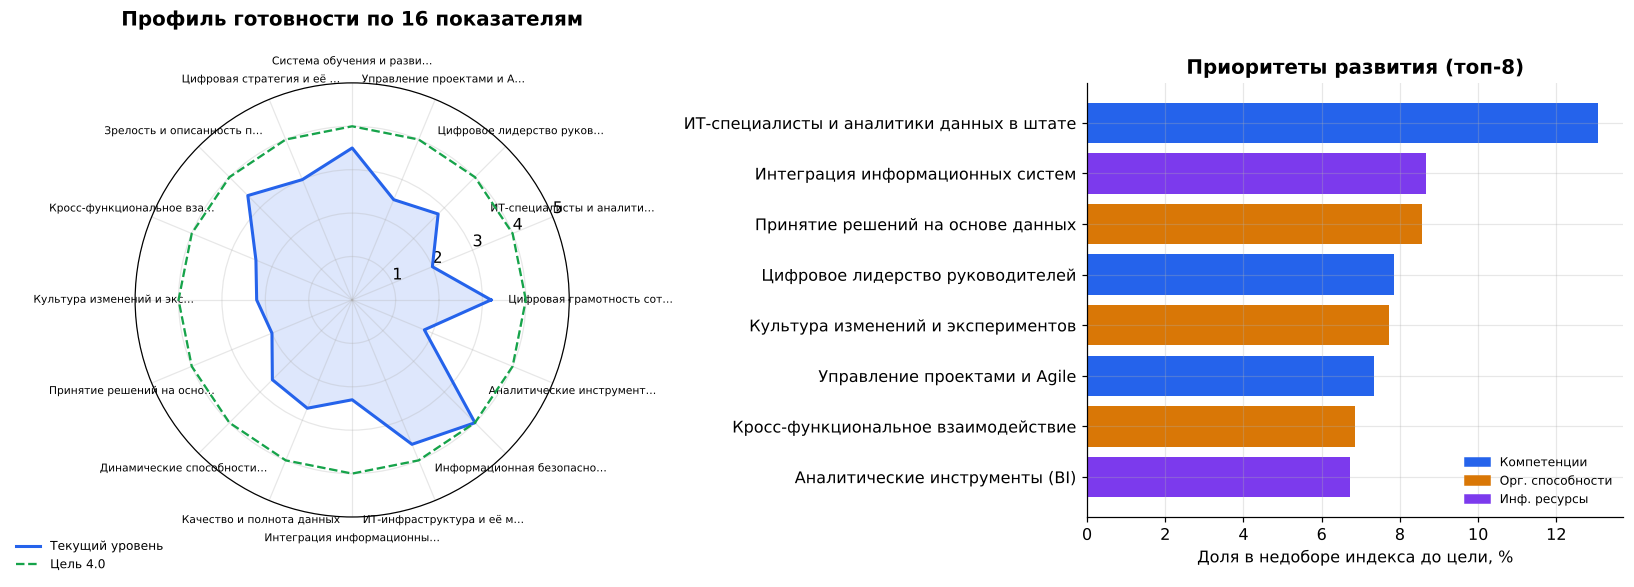

In [6]:
fig = plt.figure(figsize=(15, 5.5))
ax = fig.add_subplot(1, 2, 1, polar=True)
lbl = audit["Показатель"].tolist()
ang = np.linspace(0, 2 * np.pi, len(lbl), endpoint=False).tolist(); ang_c = ang + ang[:1]
vals = audit["Балл"].tolist() + audit["Балл"].tolist()[:1]
ax.plot(ang_c, vals, lw=2, color=PALETTE[0], label="Текущий уровень"); ax.fill(ang_c, vals, alpha=0.15, color=PALETTE[0])
ax.plot(ang_c, [target] * len(ang_c), ls="--", color=PALETTE[2], label="Цель 4.0")
ax.set_xticks(ang, [l if len(l) < 26 else l[:24] + "…" for l in lbl], fontsize=7)
ax.set_ylim(0, 5); ax.set_title("Профиль готовности по 16 показателям", pad=20)
ax.legend(loc="lower left", bbox_to_anchor=(-0.3, -0.15), fontsize=8)
ax = fig.add_subplot(1, 2, 2)
p = prio.head(8).iloc[::-1]
ax.barh(p["Показатель"], p["Доля недобора, %"], color=[{"Компетенции": PALETTE[0], "Орг. способности": PALETTE[3], "Инф. ресурсы": PALETTE[4]}[d] for d in p["Направление"]])
ax.set_xlabel("Доля в недоборе индекса до цели, %"); ax.set_title("Приоритеты развития (топ-8)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=l) for l, c in [("Компетенции", PALETTE[0]), ("Орг. способности", PALETTE[3]), ("Инф. ресурсы", PALETTE[4])]], fontsize=8)
plt.tight_layout(); plt.show()

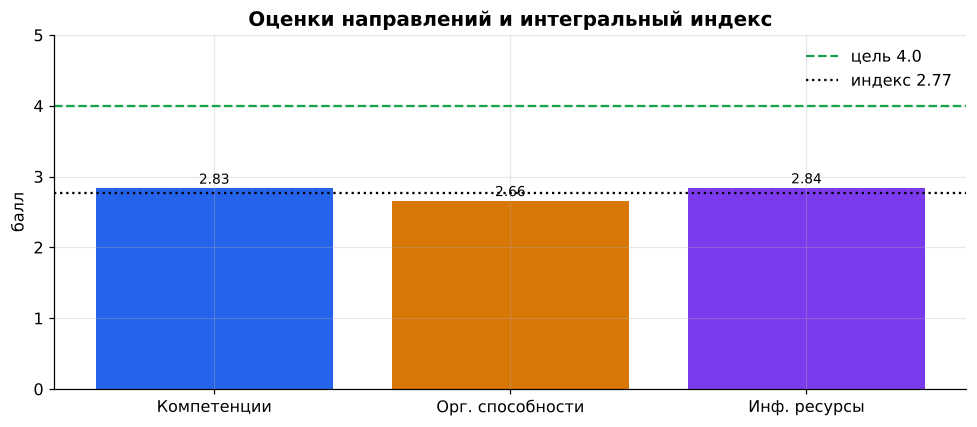

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(areas.index, areas["Оценка (1–5)"], color=[PALETTE[0], PALETTE[3], PALETTE[4]]); bar_labels(ax, bars, "{:.2f}")
ax.axhline(target, ls="--", color=PALETTE[2], label="цель 4.0"); ax.axhline(I, ls=":", color="black", label=f"индекс {I:.2f}")
ax.set_ylim(0, 5); ax.set_ylabel("балл"); ax.set_title("Оценки направлений и интегральный индекс"); ax.legend()
plt.tight_layout(); plt.show()

## 6. Интерпретация результатов

- **Компетенции около 2,8**, слабое место: почти нет ИТ-специалистов и аналитиков данных, руководители не умеют управлять
  цифровыми проектами. Сильная сторона система обучения (3,5): есть на чём развивать людей.
- **Организационные способности около 2,7**, самое отстающее направление: культура изменений, работа между отделами
  и управление по данным на начальном уровне. Это главный барьер. По RBV именно такие способности трудно скопировать,
  и их нельзя купить вместе с программой.
- **Информационные ресурсы около 2,8**, картина неровная: инфраструктура и безопасность развиты (3,6–4,0),
  но данные разрознены, интеграции слабые, BI нет.
- **Общий индекс около 2,8 из 5 (44 %)**, это **средняя готовность, ближе к нижней границе**. Трансформация возможна,
  но крупные вложения в ИТ сейчас могут не дать эффекта (парадокс Солоу). Вывод не зависит от весов направлений:
  во всех вариантах индекс 2,7–2,8.
- Примерно половина отставания от цели приходится на 5 показателей. Если поднять их до 3,5, индекс вырастет примерно до 3,2.
- **По VRIO:** инфраструктура и безопасность ценны, но не редки, они есть у всех госорганизаций. Это паритет, а не преимущество.
  Преимущество могли бы дать данные о заявителях и умение ими пользоваться, но их пока нет.

## 7. Выводы и рекомендации

**Вывод:** готовность средняя (I около 2,8). Начинать надо не с покупки систем, а с людей, процессов и данных.

**План развития на 3 года**
| Приоритет | Направление | Что делать | Целевой балл |
|---|---|---|---|
| 1 | Орг. способности | Управление по данным: единая витрина данных, еженедельные дашборды KPI для руководителей | 2,0 → 3,5 |
| 2 | Компетенции | Офис данных: 5–7 аналитиков, директор по цифровой трансформации, программа «цифровой резерв» | 2,0 → 3,5 |
| 3 | Инф. ресурсы | BI и мастер-данные (почистить реестр заявителей) | 1,8 → 3,5 |
| 4 | Орг. способности | Культура изменений: пилоты с быстрым результатом, поощрять эксперименты | 2,2 → 3,5 |
| 5 | Орг. способности | Команды из разных отделов по ключевым услугам | 2,4 → 3,5 |
| 6 | Инф. ресурсы | Интеграционная шина вместо обмена файлами | 2,3 → 3,5 |
| 7 | Компетенции | Обучение руководителей цифровому лидерству, Agile-проекты | 2,5–2,8 → 3,5 |

**Принципы:** (1) вкладывать в ИТ только вместе с изменением процессов и обучением; (2) повторять оценку каждый год
и привязать индекс к KPI руководителей; (3) сохранять сильные стороны (инфраструктура, безопасность): это база,
но не источник преимущества.